In [1]:
from pathlib import Path
import mne
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().parent
eeg_file = project_root / "data" / "raw" / "chb01" / "chb01_03.edf"
print(eeg_file)
print("Exists:", eeg_file.exists()) #checks if chb01_03 can be read

raw = mne.io.read_raw_edf(
    eeg_file,
    preload=True,
    verbose=False
)


sfreq = raw.info["sfreq"]

raw_filtered = raw.copy()

raw_filtered.filter(
    l_freq=0.5,
    h_freq=40,
    picks="eeg"
)



c:\seizure-detection-ML-project\data\raw\chb01\chb01_03.edf
Exists: True


C:\Users\rahma\AppData\Local\Temp\ipykernel_12156\2461959770.py:12: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1691 samples (6.605 s)



<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

In [2]:

"""
Welch's PSD breaks the signal into smaller overlapping sections,
estimates the power spectrum of each, then averages them.
This gives a more stable estimate for the power at different freqs.
"""

start_time = 3000
end_time = 3005;
start_sample = int(sfreq * start_time)
end_sample = int(sfreq * end_time)
window_data, window_times = raw_filtered.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
window_uv = window_data[0] * 1e6
print(window_uv.shape)

(1280,)


In [3]:
from scipy.signal import welch
freqs, psd_values = welch(
    window_uv,
    fs=sfreq,
    nperseg=512,
    noverlap=256
)

print(freqs.shape)
print(psd_values.shape)
print(freqs[:10])


(257,)
(257,)
[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5]


In [4]:
freq_mask = (freqs >= 0.5) & (freqs <= 40)
freqs_filtered = freqs[freq_mask]
psd_filtered = psd_values[freq_mask]

print(freqs_filtered[:5])
print(freqs_filtered[-5:])
print(freqs_filtered.shape)

[0.5 1.  1.5 2.  2.5]
[38.  38.5 39.  39.5 40. ]
(80,)


In [5]:
delta_mask = (freqs_filtered >= 0.5) & (freqs_filtered <= 4)
delta_freqs = freqs_filtered[delta_mask]
delta_psd = psd_filtered[delta_mask]

print("Delta frequencies:", delta_freqs)
print("Delta PSD values:", delta_psd)

#This produces multiple delta power values for each of its frequencies
#We want a single value for all the frequencies
#This can be done by taking the integral from 0.5 to 4 of the PSD delta function
#to find its area under that curve

delta_power = np.trapezoid(
    delta_psd,
    delta_freqs
)

print("Delta power:", delta_power)

Delta frequencies: [0.5 1.  1.5 2.  2.5 3.  3.5 4. ]
Delta PSD values: [1102.80924721 1146.2337621   476.98033846  953.10159812 1537.46687537
  683.06233889  237.68961689  219.81082246]
Delta power: 2847.922282333112


In [6]:
theta_mask = (freqs_filtered >= 4) & (freqs_filtered <= 8)
theta_freqs = freqs_filtered[theta_mask]
theta_psd = psd_filtered[theta_mask]

print("Theta freqs: ", theta_freqs)
print("Theta PSD values ", theta_psd)

theta_power = np.trapezoid(
    theta_psd,
    theta_freqs
)

print("Theta power: ", theta_power)

Theta freqs:  [4.  4.5 5.  5.5 6.  6.5 7.  7.5 8. ]
Theta PSD values  [219.81082246 228.71262636 316.55224038 259.17919944 210.29269382
 198.1113371  114.16002776  19.16280291  37.21056919]
Theta power:  737.3408117964661


In [7]:
alpha_mask = (freqs_filtered >= 8) & (freqs_filtered <= 13)
alpha_freqs = freqs_filtered[alpha_mask]
alpha_psd = psd_filtered[alpha_mask]

print("Alpha freqs: ", alpha_freqs)
print("Alpha PSD values ", alpha_psd)
alpha_power = np.trapezoid(
    alpha_psd,
    alpha_freqs
)
print("Alpha Power: ", alpha_power)



Alpha freqs:  [ 8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13. ]
Alpha PSD values  [37.21056919 61.32242148 39.69352353 14.35395141  9.22084819 10.65520506
  6.7621566   8.13180253  8.7414301  10.22466294 26.55228899]
Alpha Power:  100.49371546455822


In [8]:
beta_mask = (freqs_filtered >= 13) & (freqs_filtered <= 30)
beta_freqs = freqs_filtered[beta_mask]
beta_psd = psd_filtered[beta_mask]

beta_power = np.trapezoid(
    beta_psd,
    beta_freqs
)
print("Beta Power: ", beta_power)

Beta Power:  175.89020830458946


In [9]:
gamma_mask = (freqs_filtered >= 30) & (freqs_filtered <= 40)
gamma_freqs = freqs_filtered[gamma_mask]
gamma_psd = psd_filtered[gamma_mask]

gamma_power = np.trapezoid(
    gamma_psd,
    gamma_freqs
)
print("Gamma power:", gamma_power)


Gamma power: 212.66663401428278


In [10]:
mean_uv = np.mean(window_uv)
std_uv = np.std(window_uv)
rms_uv = np.sqrt(np.mean(window_uv ** 2))
ptp_uv = np.ptp(window_uv)

In [11]:
feature_row = {
    "start_time": start_time,
    "end_time": end_time,
    "label": "Seizure",

    "mean_uv": mean_uv,
    "std_uv": std_uv,
    "rms_uv": rms_uv,
    "ptp_uv": ptp_uv,

    "delta_power": delta_power,
    "theta_power": theta_power,
    "alpha_power": alpha_power,
    "beta_power": beta_power,
    "gamma_power": gamma_power
}

#This represents one potential traning example for the model to learn with

print(feature_row)

{'start_time': 3000, 'end_time': 3005, 'label': 'Seizure', 'mean_uv': np.float64(-0.3202098418280066), 'std_uv': np.float64(63.35140218641775), 'rms_uv': np.float64(63.35221143202548), 'ptp_uv': np.float64(375.2431166018107), 'delta_power': np.float64(2847.922282333112), 'theta_power': np.float64(737.3408117964661), 'alpha_power': np.float64(100.49371546455822), 'beta_power': np.float64(175.89020830458946), 'gamma_power': np.float64(212.66663401428278)}


In [12]:
#Now I can take that process and generalize it into a function
from scipy.signal import welch 

def extract_features(window_uv, sfreq):
    #Time-domain features
    mean_uv = np.mean(window_uv)
    std_uv = np.std(window_uv)
    rms_uv = np.sqrt(np.mean(window_uv ** 2))
    ptp_uv = np.ptp(window_uv)

    # Frequency-domain representation
    freqs, psd_values = welch(
        window_uv,
        fs=sfreq,
        nperseg=512,
        noverlap=256
    )

    # Keep 0.5–40 Hz
    freq_mask = (freqs >= 0.5) & (freqs <= 40)
    freqs_filtered = freqs[freq_mask]
    psd_filtered = psd_values[freq_mask]

    # Band powers
    delta_mask = (freqs_filtered >= 0.5) & (freqs_filtered <= 4)
    theta_mask = (freqs_filtered >= 4) & (freqs_filtered <= 8)
    alpha_mask = (freqs_filtered >= 8) & (freqs_filtered <= 13)
    beta_mask = (freqs_filtered >= 13) & (freqs_filtered <= 30)
    gamma_mask = (freqs_filtered >= 30) & (freqs_filtered <= 40)

    delta_power = np.trapezoid(
        psd_filtered[delta_mask],
        freqs_filtered[delta_mask]
    )

    theta_power = np.trapezoid(
        psd_filtered[theta_mask],
        freqs_filtered[theta_mask]
    )

    alpha_power = np.trapezoid(
        psd_filtered[alpha_mask],
        freqs_filtered[alpha_mask]
    )

    beta_power = np.trapezoid(
        psd_filtered[beta_mask],
        freqs_filtered[beta_mask]
    )

    gamma_power = np.trapezoid(
        psd_filtered[gamma_mask],
        freqs_filtered[gamma_mask]
    )

    return {
        "mean_uv": mean_uv,
        "std_uv": std_uv,
        "rms_uv": rms_uv,
        "ptp_uv": ptp_uv,
        "delta_power": delta_power,
        "theta_power": theta_power,
        "alpha_power": alpha_power,
        "beta_power": beta_power,
        "gamma_power": gamma_power
    }

test_features = extract_features(window_uv, sfreq)
print(test_features)


{'mean_uv': np.float64(-0.3202098418280066), 'std_uv': np.float64(63.35140218641775), 'rms_uv': np.float64(63.35221143202548), 'ptp_uv': np.float64(375.2431166018107), 'delta_power': np.float64(2847.922282333112), 'theta_power': np.float64(737.3408117964661), 'alpha_power': np.float64(100.49371546455822), 'beta_power': np.float64(175.89020830458946), 'gamma_power': np.float64(212.66663401428278)}


In [13]:
window_size = 5
seizure_start = 2996
seizure_end = 3036

total_duration = int(raw_filtered.times[-1] + 1 / sfreq)
num_windows = total_duration // window_size

windows = []

for i in range(num_windows):
    start_time = i * window_size
    end_time = start_time + window_size

    if start_time >= seizure_start and end_time <= seizure_end:
        label = "Seizure"

    elif end_time <= seizure_start or start_time >= seizure_end:
        label = "Non Seizure"

    else:
        label = "Partial Seizure"

    windows.append({
        "window_index": i,
        "start_time": start_time,
        "end_time": end_time,
        "label": label
    })

windows_df = pd.DataFrame(windows)
print(windows_df.shape)
print(windows_df["label"].value_counts())

(720, 4)
label
Non Seizure        711
Seizure              7
Partial Seizure      2
Name: count, dtype: int64


In [ ]:
feature_rows = []
for _, row in windows_df.iterrows():
    if row["label"] == "Partial Seizure":
        continue

    start_sample = int(row["start_time"] * sfreq)
    end_sample = int(row["end_time"] * sfreq)

    window_data = raw_filtered.get_data(
        picks = ["FP1-F7"],
        start=start_sample,
        stop=end_sample

    )
    window_uv = window_data[0] * 1e6

    features = extract_features(window_uv, sfreq)

    features["window_index"] = row["window_index"]
    features["start_time"] = row["start_time"]
    features["end_time"] = row["end_time"]
    features["label"] = row["label"]

    feature_rows.append(features)

features_df = pd.DataFrame(feature_rows)


print(features_df.shape)
print(features_df.head())
print(features_df["label"].value_counts())
print(features_df.isna().sum())



(718, 13)
    mean_uv     std_uv     rms_uv      ptp_uv  delta_power  theta_power  \
0  1.951278  27.041129  27.111439  152.040420   418.781866    99.362901   
1 -0.064298  26.030999  26.031079  167.269432   267.604148   135.851263   
2 -1.893457  35.670337  35.720556  233.277392   467.321554   184.595270   
3  1.866653  23.432456  23.506688  127.398672   281.925569    86.028947   
4 -0.217540  30.574674  30.575448  205.380661   486.417840    66.077143   

   alpha_power  beta_power  gamma_power  window_index  start_time  end_time  \
0   328.281856   24.611284     5.077614             0           0         5   
1   109.892415   24.521486     5.877186             1           5        10   
2   337.405501   33.062063     5.240796             2          10        15   
3   141.230208   28.202189     5.680157             3          15        20   
4   162.326721   22.384302     5.515788             4          20        25   

         label  
0  Non Seizure  
1  Non Seizure  
2  Non Seizur

In [19]:
seizure_features = features_df[
    features_df["label"] == "Seizure"
]

print(
    seizure_features[
        ["window_index", "start_time", "end_time", "label"]
    ]
)

     window_index  start_time  end_time    label
599           600        3000      3005  Seizure
600           601        3005      3010  Seizure
601           602        3010      3015  Seizure
602           603        3015      3020  Seizure
603           604        3020      3025  Seizure
604           605        3025      3030  Seizure
605           606        3030      3035  Seizure


In [20]:
features_df[
    features_df["window_index"] == 600
][
    [
        "mean_uv",
        "std_uv",
        "rms_uv",
        "ptp_uv",
        "delta_power",
        "theta_power",
        "alpha_power",
        "beta_power",
        "gamma_power"
    ]
]

,mean_uv,std_uv,rms_uv,ptp_uv,delta_power,theta_power,alpha_power,beta_power,gamma_power
599,-0.32021,63.351402,63.352211,375.243117,2847.922282,737.340812,100.493715,175.890208,212.666634


In [22]:
processed_path = (
    project_root / 
    "data" /
    "processed" /
    "chb01_03_fp1-f7_engineered_features.csv"
)

features_df.to_csv(processed_path, index=False)

print("Saved:", processed_path.exists())
print("Path:", processed_path)

Saved: True
Path: c:\seizure-detection-ML-project\data\processed\chb01_03_fp1-f7_engineered_features.csv


In [23]:
feature_columns = [
    "mean_uv",
    "std_uv",
    "rms_uv",
    "ptp_uv",
    "delta_power",
    "theta_power",
    "alpha_power",
    "beta_power",
    "gamma_power"
]

summary = features_df.groupby("label")[feature_columns].median()
print(summary)

              mean_uv      std_uv      rms_uv      ptp_uv  delta_power  \
label                                                                    
Non Seizure -0.006532   29.373122   29.382187  190.345584   439.055641   
Seizure     -0.320210  100.261640  100.264252  673.732619  8898.802143   

             theta_power  alpha_power  beta_power  gamma_power  
label                                                           
Non Seizure   140.859124    80.010154   22.429135     5.868343  
Seizure      1229.315817    94.366262  268.154570   212.666634  


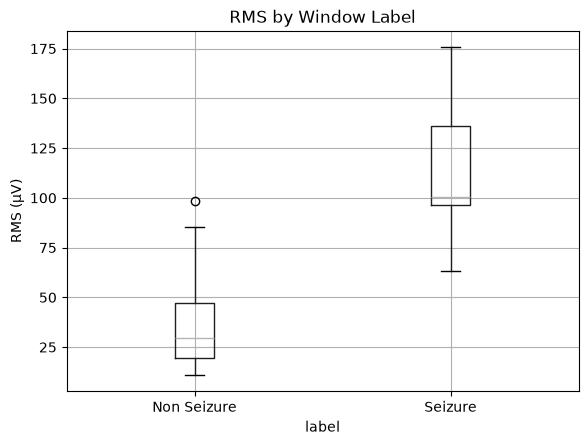

In [24]:
import matplotlib.pyplot as plt

features_df.boxplot(
    column="rms_uv",
    by="label"
)

plt.title("RMS by Window Label")
plt.suptitle("")
plt.ylabel("RMS (µV)")
plt.show()

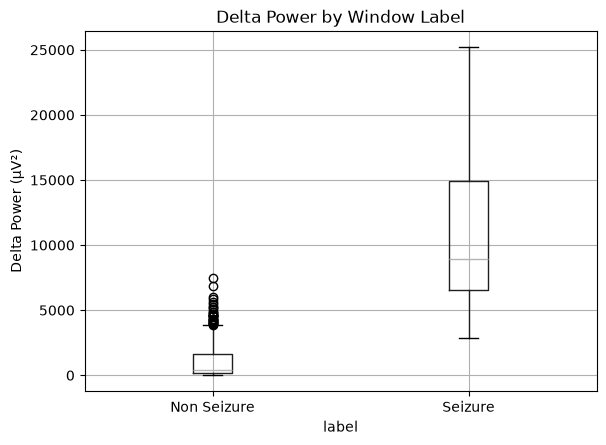

In [25]:
features_df.boxplot(
    column="delta_power",
    by="label"
)

plt.title("Delta Power by Window Label")
plt.suptitle("")
plt.ylabel("Delta Power (µV²)")
plt.show()

In Notebook 4, I expanded my features to include both time-domain, as I had previously, and now frequency-domain which was seperated into different masks (Alpha, Delta, Gamma, etc.). I also used Welch's method to estimate the PSD of each window, and band power was calculated by integrating the PSD across each frequency band. 